<a href="https://colab.research.google.com/github/skmanyakaveramma-rgb/DAV/blob/main/Lab8_DAV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score
)

In [3]:
df = pd.read_csv("/content/archive (1).zip")
df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")
import pandas as pd
from sklearn.model_selection import train_test_split
df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})
print(df.shape)
print(df.head())
print("\nClass balance (1 = malignant):\n", df["diagnosis"].value_counts())
print("\nMissing values:", df.isnull().sum().sum())

(569, 31)
   diagnosis  radius_mean  ...  symmetry_worst  fractal_dimension_worst
0          1        17.99  ...          0.4601                  0.11890
1          1        20.57  ...          0.2750                  0.08902
2          1        19.69  ...          0.3613                  0.08758
3          1        11.42  ...          0.6638                  0.17300
4          1        20.29  ...          0.2364                  0.07678

[5 rows x 31 columns]

Class balance (1 = malignant):
 diagnosis
0    357
1    212
Name: count, dtype: int64

Missing values: 0


In [4]:
X = df.drop(columns="diagnosis")
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [5]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
model = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(max_iter=1000))
])
model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('logreg', LogisticRegression(max_iter=1000))])

In [7]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

# Compute confusion matrix and extract values
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print(f"\nConfusion matrix:\n", cm)
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}\n")


Confusion matrix:
 [[71  1]
 [ 3 39]]
TN=71  FP=1  FN=3  TP=39



Accuracy :  0.9649
Precision:  0.975
Recall   :  0.9286
F1-score :  0.9512
ROC-AUC  :  0.996

Full report:
               precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



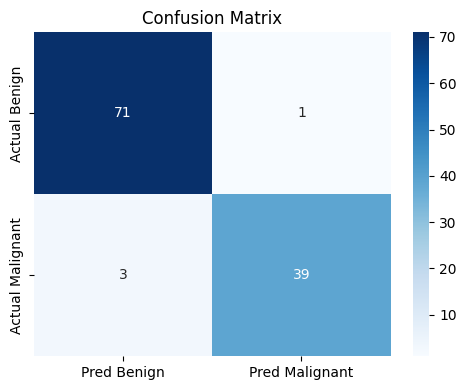

In [9]:
print("Accuracy : ", round(accuracy_score(y_test, y_pred), 4))
print("Precision: ", round(precision_score(y_test, y_pred), 4))
print("Recall   : ", round(recall_score(y_test, y_pred), 4))
print("F1-score : ", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC  : ", round(roc_auc_score(y_test, y_prob), 4))

print("\nFull report:\n", classification_report(y_test, y_pred, target_names=["Benign", "Malignant"]))
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred Benign", "Pred Malignant"],
            yticklabels=["Actual Benign", "Actual Malignant"])

plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [10]:
coef_df = pd.DataFrame({
    "feature": X.columns,
    "coefficient": model.named_steps["logreg"].coef_[0],
}).sort_values("coefficient", ascending=False)

print(f"Top 5 features pushing towards MALIGNANT:\n", coef_df.head(5))
print(f"\nTop 5 features pushing towards BENIGN:\n", coef_df.tail(5))

Top 5 features pushing towards MALIGNANT:
                 feature  coefficient
21        texture_worst     1.434093
10            radius_se     1.233325
28       symmetry_worst     1.061264
7   concave points_mean     0.952813
26      concavity_worst     0.911406

Top 5 features pushing towards BENIGN:
                  feature  coefficient
18           symmetry_se    -0.330658
11            texture_se    -0.407611
5       compactness_mean    -0.439546
19  fractal_dimension_se    -0.593876
15        compactness_se    -0.906925


In [11]:
print("\nThreshold Precision Recall    F1")

for t in [0.1, 0.3, 0.5, 0.7, 0.9]:
    pred_t = (y_prob >= t).astype(int)
    print(f"{t:.1f}         {precision_score(y_test, pred_t, zero_division=0):.3f}   {recall_score(y_test, pred_t):.3f}    {f1_score(y_test, pred_t):.3f}")


Threshold Precision Recall    F1
0.1         0.891   0.976    0.932
0.3         0.976   0.976    0.976
0.5         0.975   0.929    0.951
0.7         1.000   0.905    0.950
0.9         1.000   0.786    0.880
